# MovieLens 100K: Exploratory Data Analysis

This notebook explores the MovieLens 100K dataset to understand its structure, rating distributions, user and movie activity, and data quality before implementing recommendation models.

## 1. Dataset Overview

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import GENRE_COLS, load_movielens

sns.set_theme(style="whitegrid")

### Load Dataset

In [2]:
ratings, movies, users = load_movielens()

### Verify Dataset Dimensions

In [3]:
for name, df in zip(["Ratings", "Movies", "Users"], [ratings, movies, users]):
    print(f"{name}: {df.shape}")

Ratings: (100000, 4)
Movies: (1682, 24)
Users: (943, 5)


### Examine Unique Users and Movies

In [4]:
# We wish to determine the number of distinct users and movies in the ratings data.
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies:", ratings["movie_id"].nunique())
print("Total ratings:", len(ratings))

Unique users: 943
Unique movies: 1682
Total ratings: 100000


## 2. Rating Distribution

### Rating Frequencies

In [5]:
freq = ratings["rating"].value_counts().sort_index()
percentage = (freq / len(ratings)) * 100

rating_distribution = pd.DataFrame({
    "Frequency": freq,
    "Percentage (%)": percentage
})

display(rating_distribution)

,Frequency,Percentage (%)
rating,,
1,6110,6.110
2,11370,11.370
3,27145,27.145
4,34174,34.174
5,21201,21.201


### Descriptive Statistics

In [6]:
display(ratings["rating"].describe())

print("Median rating:", ratings["rating"].median())
print("Mode rating:", ratings["rating"].mode().tolist())

count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Median rating: 4.0
Mode rating: [4]


### Visualize Rating Distribution

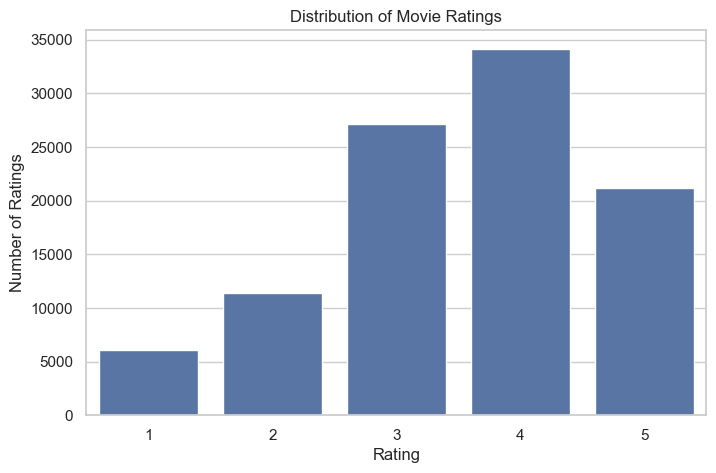

In [7]:
# Visualization of Rating Distribution
# This shows how frequently users assign each rating
plt.figure(figsize=(8, 5))
sns.barplot(x=freq.index, y=freq.values)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(range(5), [1, 2, 3, 4, 5])

plt.show()

## 3. Movie Activity Analysis

### Ratings per Movie

In [8]:
movie_activity = ratings.groupby("movie_id").size()

display(movie_activity.describe())

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
dtype: float64

### Most Frequently Rated Movies

In [9]:
top_movies = (
    movie_activity
    .nlargest(10)
    .rename("rating_count")
    .reset_index()
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
    .sort_values("rating_count", ascending=False)
)

display(top_movies[["movie_id", "title", "rating_count"]])

,movie_id,title,rating_count
0,50,Star Wars (1977),583
1,258,Contact (1997),509
2,100,Fargo (1996),508
3,181,Return of the Jedi (1983),507
4,294,Liar Liar (1997),485
5,286,"English Patient, The (1996)",481
6,288,Scream (1996),478
7,1,Toy Story (1995),452
8,300,Air Force One (1997),431
9,121,Independence Day (ID4) (1996),429


### Movie Activity Distribution

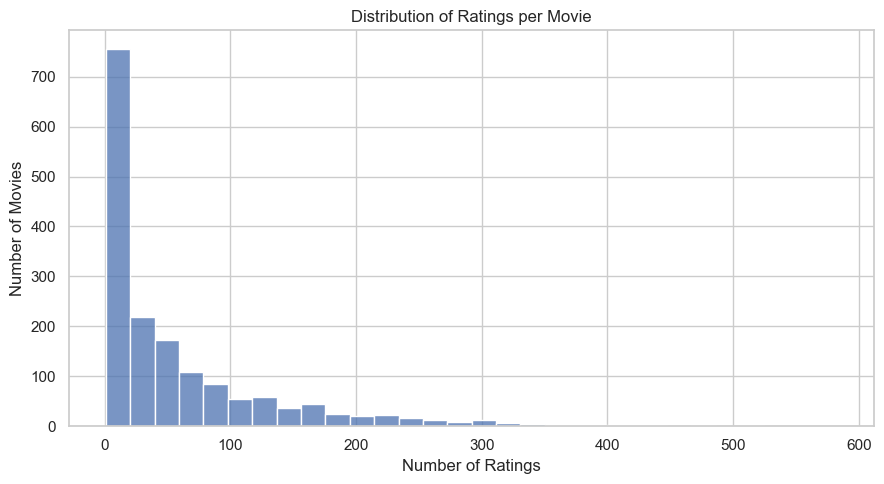

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(movie_activity, bins=30)

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

## 4. User Activity Analysis

### Ratings per User

In [11]:
user_activity = ratings.groupby("user_id").size()

display(user_activity.describe())

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64

### Most Active Users

In [12]:
top_users = (
    user_activity
    .nlargest(10)
    .rename("rating_count")
    .reset_index()
)

display(top_users)

,user_id,rating_count
0,405,737
1,655,685
2,13,636
3,450,540
4,276,518
5,416,493
6,537,490
7,303,484
8,234,480
9,393,448


### User Activity Distribution

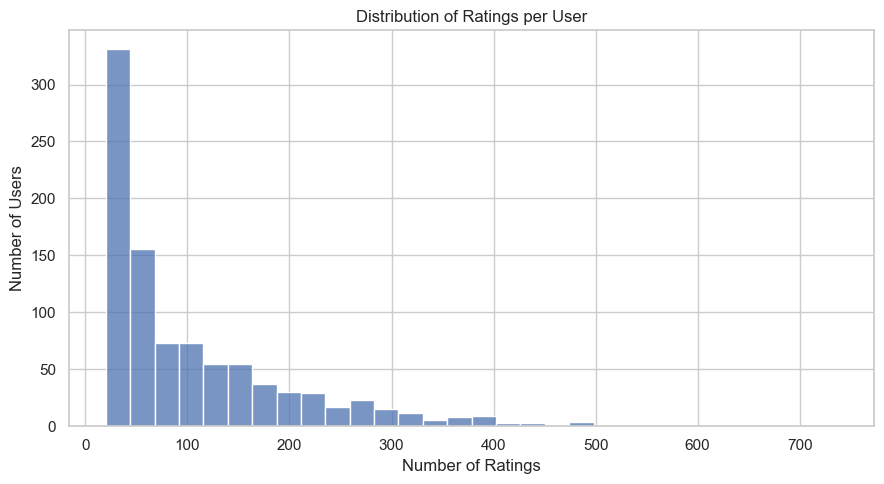

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(user_activity, bins=30)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

## 5. Data Quality Assessment

### Missing Values

In [14]:
print("Missing values in ratings:")
display(ratings.isnull().sum())

print("Missing values in movies:")
display(movies.isnull().sum())

print("Missing values in users:")
display(users.isnull().sum())

Missing values in ratings:


user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Missing values in movies:


movie_id                 0
title                    0
release_date             1
video_release_date    1682
imdb_url                 3
unknown                  0
Action                   0
Adventure                0
Animation                0
Children's               0
Comedy                   0
Crime                    0
Documentary              0
Drama                    0
Fantasy                  0
Film-Noir                0
Horror                   0
Musical                  0
Mystery                  0
Romance                  0
Sci-Fi                   0
Thriller                 0
War                      0
Western                  0
dtype: int64

Missing values in users:


user_id       0
age           0
gender        0
occupation    0
zip_code      0
dtype: int64

### Duplicate Records

In [15]:
print("Duplicate rating records:", ratings.duplicated().sum())
print("Duplicate movie records:", movies.duplicated().sum())
print("Duplicate user records:", users.duplicated().sum())

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(subset=["user_id", "movie_id"]).sum()
)

dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
print("Movies sharing a duplicate title:", len(dup_titles))
print("Duplicate titles:", dup_titles["title"].nunique())
display(dup_titles[["movie_id", "title"]].head(6))

Duplicate rating records: 0
Duplicate movie records: 0
Duplicate user records: 0
Duplicate user-movie pairs: 0
Movies sharing a duplicate title: 36
Duplicate titles: 18


,movie_id,title
572,573,Body Snatchers (1993)
669,670,Body Snatchers (1993)
1644,1645,"Butcher Boy, The (1998)"
1649,1650,"Butcher Boy, The (1998)"
1233,1234,Chairman of the Board (1998)
1653,1654,Chairman of the Board (1998)


### Invalid Ratings

In [16]:
invalid_ratings = ratings[
    ~ratings["rating"].between(1, 5)
]

print("Invalid ratings:", len(invalid_ratings))
display(invalid_ratings.head())

Invalid ratings: 0


,user_id,movie_id,rating,timestamp


### Dataset Consistency

In [17]:
missing_users = set(ratings["user_id"]) - set(users["user_id"])
missing_movies = set(ratings["movie_id"]) - set(movies["movie_id"])

print("User IDs without metadata:", len(missing_users))
print("Movie IDs without metadata:", len(missing_movies))

User IDs without metadata: 0
Movie IDs without metadata: 0


## 6. Genre and Sparsity Analysis

### Matrix Sparsity and Time Span

In [18]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
sparsity = 1 - len(ratings) / (n_users * n_movies)

print(f"Matrix sparsity: {sparsity * 100:.2f}% ({len(ratings):,} of {n_users * n_movies:,} pairs rated)")

dates = pd.to_datetime(ratings["timestamp"], unit="s")
print(f"Earliest rating: {dates.min()}")
print(f"Latest rating:   {dates.max()}")
print(f"Span in days:    {(dates.max() - dates.min()).days}")

Matrix sparsity: 93.70% (100,000 of 1,586,126 pairs rated)
Earliest rating: 1997-09-20 03:05:10
Latest rating:   1998-04-22 23:10:38
Span in days:    214


### Positive Rating Split (rating >= 4)

In [19]:
positive = ratings["rating"] >= 4
print(f"Positive ratings (>= 4): {positive.sum():,} ({positive.mean() * 100:.2f}%)")
print(f"Ratings below 4:         {(~positive).sum():,} ({(~positive).mean() * 100:.2f}%)")

pos_per_user = ratings.assign(positive=positive).groupby("user_id")["positive"].sum()
display(pos_per_user.describe())
print("Users with 0 positive ratings:", int((pos_per_user == 0).sum()))

Positive ratings (>= 4): 55,375 (55.38%)
Ratings below 4:         44,625 (44.62%)


count    943.000000
mean      58.722163
std       54.701130
min        0.000000
25%       19.000000
50%       39.000000
75%       80.500000
max      378.000000
Name: positive, dtype: float64

Users with 0 positive ratings: 1


### Genre Distribution

Unique genre flag values: [0, 1]
Movies with no genres listed: 0


,movie_id,title
266,267,unknown
1372,1373,Good Morning (1971)


count    1682.000000
mean        1.719976
std         0.868207
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         6.000000
dtype: float64

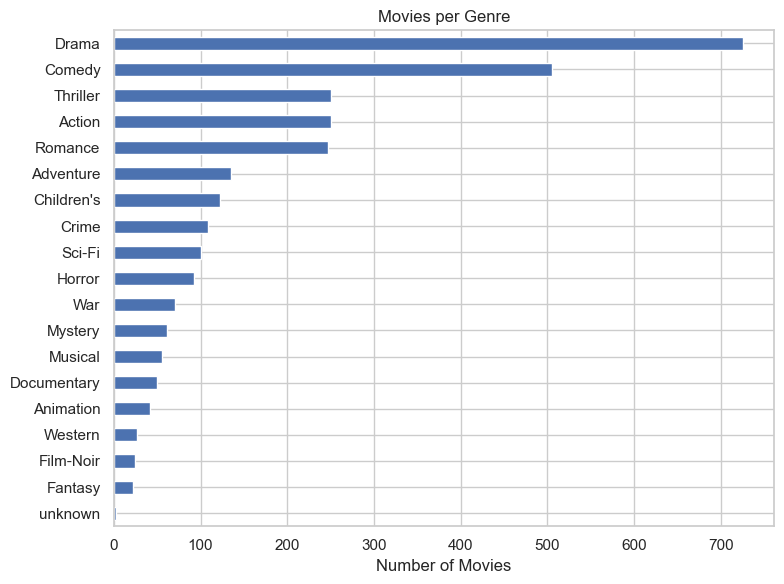

In [20]:
genre_flags = movies[GENRE_COLS]
print("Unique genre flag values:", sorted(pd.unique(genre_flags.to_numpy().ravel()).tolist()))
print("Movies with no genres listed:", int((genre_flags.sum(axis=1) == 0).sum()))
display(movies[movies["unknown"] == 1][["movie_id", "title"]])
display(genre_flags.sum(axis=1).describe())

genre_counts = genre_flags.sum().sort_values(ascending=True)
plt.figure(figsize=(8, 6))
genre_counts.plot(kind="barh")
plt.title("Movies per Genre")
plt.xlabel("Number of Movies")
plt.tight_layout()
plt.show()

### Minimum Ratings Threshold Coverage

,min_ratings,movies_kept,catalog_pct,ratings_pct
0,1,1682,100.00,100.00
1,10,1152,68.49,97.95
2,25,872,51.84,93.50
3,50,603,35.85,83.72
4,100,338,20.10,64.82
5,200,118,7.02,33.68


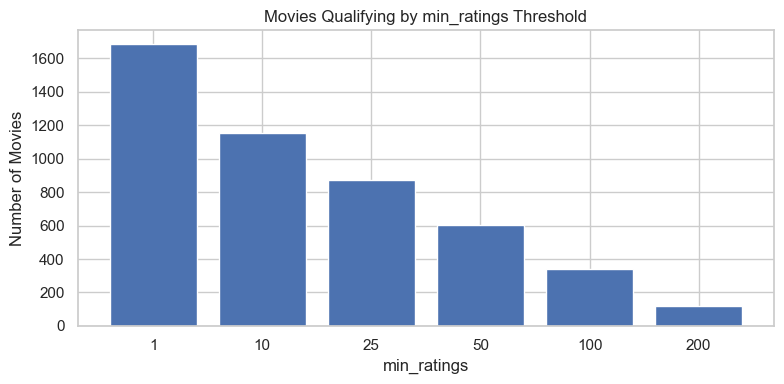

In [21]:
rows = []
for min_r in [1, 10, 25, 50, 100, 200]:
    kept = movie_activity[movie_activity >= min_r]
    rows.append({
        "min_ratings": min_r,
        "movies_kept": len(kept),
        "catalog_pct": 100 * len(kept) / len(movies),
        "ratings_pct": 100 * kept.sum() / len(ratings),
    })

min_ratings_df = pd.DataFrame(rows)
display(min_ratings_df.round(2))

plt.figure(figsize=(8, 4))
plt.bar(min_ratings_df["min_ratings"].astype(str), min_ratings_df["movies_kept"])
plt.title("Movies Qualifying by min_ratings Threshold")
plt.xlabel("min_ratings")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## 7. Key Findings

### Dataset Overview

The MovieLens 100K dataset contains 100,000 ratings from 943 users across 1,682 movies. All three tables (`ratings`: 100,000 rows, `movies`: 1,682 rows, `users`: 943 rows) match cleanly on `user_id` and `movie_id`. Out of 1,586,126 possible user-movie pairs, 93.70% are empty. The ratings were collected over 214 days between September 20, 1997 and April 22, 1998.

### Rating Distribution

Ratings tend to be positive on the 1-5 scale. The average rating is 3.53 (standard deviation 1.13), with both a median and mode of 4. A rating of 4 makes up 34.17% of the dataset (34,174 ratings), followed by 3 (27.14%, 27,145), 5 (21.20%, 21,201), 2 (11.37%, 11,370), and 1 (6.11%, 6,110). Using `threshold=4` splits the data into 55,375 positive ratings (55.38%) and 44,625 ratings below 4 (44.62%). Most users have plenty of positive ratings (median 39, mean 58.72), though 1 user has 0 positive ratings.

### Movie Activity

Rating counts per movie are skewed toward a small group of popular titles. The mean is 59.45 ratings per movie, the median is 27, and a quarter of all movies have 6 or fewer ratings. *Star Wars (1977)* has the most ratings at 583, followed by *Contact (1997)* (509), *Fargo (1996)* (508), and *Return of the Jedi (1983)* (507). With `min_ratings=50`, 603 out of 1,682 movies (35.85% of the catalog) qualify for the popularity model, covering 83.72% of all ratings.

### User Activity

Users rated between 20 and 737 movies, with a mean of 106.04 and a median of 65.0 (interquartile range 33 to 148). The most active user (`user_id` 405) submitted 737 ratings. Because every user has at least 20 ratings, an 80/20 time-based split always leaves every user with at least 16 training ratings and 4 test ratings.

### Data Quality

There are no missing values in `ratings` or `users`, no duplicate rows in any table, no duplicate `(user_id, movie_id)` pairs, no ratings outside 1-5, and no unmatched user or movie IDs. In `movies`, `video_release_date` is empty across all 1,682 rows, `imdb_url` is missing 3 entries, and `release_date` is missing 1 entry, none of which are used by our models. There are 36 movie entries that share 18 duplicate titles under separate `movie_id` values (such as *Body Snatchers (1993)* and *Chasing Amy (1997)*), so models need to match on `movie_id` rather than title. All 19 `GENRE_COLS` flags are binary 0 or 1, with an average of 1.72 genres per movie (Drama is most common at 725 movies, followed by Comedy at 505). Two movies (`movie_id` 267 and `movie_id` 1373) carry the `unknown` genre flag.

### Conclusion

Overall, the dataset is clean on the columns needed for recommendation (`user_id`, `movie_id`, `rating`, `timestamp`, and genre flags). The high sparsity (93.70%) and skewed movie counts explain why `min_ratings=50` helps filter out rare movies in the popularity baseline, while keeping 83.72% of rating volume. At the same time, sharing only 19 binary genre labels (usually 1 or 2 per movie) means many unrated movies tie on cosine similarity and need rating counts to break ties.